# High-pass filter rekursif Pan-Tompkins: derivasi, pembuktian, dan fixed-point

Notebook ini menurunkan, membuktikan, dan memplot high-pass filter rekursif Pan-Tompkins,
persamaan (6) pada paper Pan dan Tompkins 1985 halaman 232:

$$ y[n] = 32\,x[n-16] - \left[ y[n-1] + x[n] - x[n-32] \right] $$

Setiap angka yang diklaim dihitung di cell tempat angka itu dicetak. Notebook ini adalah pasangan
dari `low-pass-filter-equation.ipynb` yang membahas persamaan (3) dan (5) paper yang sama.

Isi notebook:

1. Difference equation, setup, identitas interpreter, dan koefisien filter.
2. Notasi seluruh variabel.
3. Tiga langkah derivasi: buka bracket, kumpulkan suku rekurens, selesaikan dengan unrolling.
4. Worked case impulse dan unit step dengan tabel per suku, sama seperti perhitungan tangan.
5. Transfer function $H(z)$, split dua cabang, dan identitas deret hingga 32 tap.
6. Amplitudo response persamaan (5), pole, zero, impulse response, dan magnitude response pada 200 Hz dan 250 Hz.
7. Kasus sebelum dan sesudah pada sinyal ECG 250 Hz dengan baseline wander, mains 50 Hz, dan muscle noise.
8. Pole Nyquist, fixed-point int16, dan headroom 32.
9. Tabel ringkasan seluruh angka terukur.

## 1. Difference equation

Paper Pan dan Tompkins 1985 menuliskan high-pass filter pada persamaan (4), (5), dan (6):
transfer function, amplitude response, dan difference equation. Notebook ini memakai difference
equation persamaan (6) sebagai titik tolak:

$$ y[n] = 32\,x[n-16] - \left[ y[n-1] + x[n] - x[n-32] \right] $$

Initial condition nol, sesuai implementasi di FPGA dan MCU saat start:

$$ y[n] = 0 \ \text{untuk} \ n < 0, \qquad x[n] = 0 \ \text{untuk} \ n < 0 $$

Bentuk yang setara setelah bracket dibuka:

$$ y[n] = 32\,x[n-16] - y[n-1] - x[n] + x[n-32] $$

Numerator memiliki 33 tap, yaitu -1 di index 0, +32 di index 16, dan +1 di index 32.
Denominator adalah $1 + z^{-1}$, sehingga filter ini punya satu pole, dan pole itu ada di $z = -1$.
Paper menyebut gain 32 dan delay 16 sample untuk tahap ini. Gain 32 pada paper adalah gain
numerator, sedangkan DC gain terukur dari kedua vektor di bawah dicetak di cell ini setelah
seluruh koefisien dibentuk.

In [1]:
# Tujuan: menyiapkan library, identitas interpreter, konstanta sampling, dan koefisien filter yang dipakai seluruh notebook.
# Cell ini mencetak difference equation yang diimplementasikan, vektor numerator 33 tap, vektor denominator,
# koefisien low-pass pasangan, dan koefisien lima titik derivative.

%matplotlib inline

import sys
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
from scipy import signal as sg

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True})
pd.set_option("display.width", 200)

FS_PAPER = 200.0   # sampling frequency paper Pan-Tompkins
FS_BOARD = 250.0   # sampling frequency board tim

print("difference equation yang diimplementasikan, persamaan (6) paper Pan-Tompkins halaman 232:")
print("  y[n] = 32*x[n-16] - [ y[n-1] + x[n] - x[n-32] ]")
print("  y[n] = 32*x[n-16] - y[n-1] - x[n] + x[n-32]")
print("  initial condition nol: x[n] = 0 dan y[n] = 0 untuk n < 0")
print()

# Numerator 33 tap: -1 di index 0, +32 di index 16, +1 di index 32.
# Template integer dibuat lebih dulu supaya pemeriksaan koefisien memakai aritmetika eksak.
B_HP_INT = np.zeros(33, dtype=np.int64)
B_HP_INT[0] = -1
B_HP_INT[16] = 32
B_HP_INT[32] = 1
B_HP = B_HP_INT.astype(float)
# Denominator 1 + z^-1
A_HP_INT = np.array([1, 1], dtype=np.int64)
A_HP = A_HP_INT.astype(float)

# Low-pass Pan-Tompkins dari notebook pasangan, dipakai sebagai tahap berikutnya di rantai.
# DC gain dinormalisasi ke 1 supaya amplitudo antar tahap sebanding.
H_FIR = np.convolve(np.ones(6), np.ones(6))
H_LP = H_FIR / H_FIR.sum()
# Lima titik derivative, persamaan (9) paper digeser dua sample agar kausal
B_DER = np.array([2.0, 1.0, 0.0, -1.0, -2.0]) / 8.0

HASIL = {}   # kumpulan angka terukur, dicetak sebagai tabel di bagian 16

print("interpreter :", sys.executable)
print("python      :", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| pandas", pd.__version__)
print("fs paper    :", FS_PAPER, "Hz | fs board :", FS_BOARD, "Hz")
print()
index_harap = np.array([0, 16, 32], dtype=np.int64)
tap_harap = np.array([-1, 32, 1], dtype=np.int64)
dc_gain = float(B_HP_INT.sum() / A_HP_INT.sum())
sum_der = float(B_DER.sum())

print("B_HP_INT numerator 33 tap, template integer :", B_HP_INT)
print("B_HP sebagai float                         :", B_HP.astype(int))
print("jumlah tap                                 :", B_HP_INT.size,
      "| koefisien tak nol :", int(np.count_nonzero(B_HP_INT)))
print("index dan nilai tak nol                    :", np.flatnonzero(B_HP_INT),
      B_HP_INT[np.flatnonzero(B_HP_INT)])
print("A_HP_INT denominator                       :", A_HP_INT, "yaitu 1 + z^-1")
print("DC gain dari kedua vektor, numerator di z = 1 :", float(B_HP_INT.sum()),
      "| denominator di z = 1 :", float(A_HP_INT.sum()), "| DC gain :", dc_gain)
print("galat DC gain terhadap 16                  :", abs(dc_gain - 16.0))
print("H_LP low-pass pasangan                     :", H_LP, "| sum =", float(H_LP.sum()))
print("B_DER lima titik                           :", B_DER, "| sum =", sum_der,
      "| galat terhadap nol :", abs(sum_der))

assert B_HP_INT.size == 33, "numerator harus 33 tap"
assert np.array_equal(np.flatnonzero(B_HP_INT), index_harap), "index tak nol harus 0, 16, 32"
assert np.array_equal(B_HP_INT[index_harap], tap_harap), "nilai tak nol harus -1, +32, +1"
assert int(np.count_nonzero(B_HP_INT)) == 3, "hanya tiga tap yang tidak nol"
assert np.array_equal(A_HP_INT, np.array([1, 1], dtype=np.int64)), "denominator harus 1 + z^-1"
assert abs(dc_gain - 16.0) < 1e-12, "DC gain harus 16"
assert abs(sum_der) < 1e-15, "derivative harus punya gain nol di DC"

HASIL["jumlah tap numerator"] = 33
HASIL["jumlah koefisien tak nol"] = 3
HASIL["DC gain terukur"] = dc_gain
print("lolos: numerator 33 tap dengan koefisien -1, +32, +1, denominator 1 + z^-1, dan DC gain", dc_gain)

difference equation yang diimplementasikan, persamaan (6) paper Pan-Tompkins halaman 232:
  y[n] = 32*x[n-16] - [ y[n-1] + x[n] - x[n-32] ]
  y[n] = 32*x[n-16] - y[n-1] - x[n] + x[n-32]
  initial condition nol: x[n] = 0 dan y[n] = 0 untuk n < 0

interpreter : /home/avivsabilalm/.venvs/jupyter/bin/python
python      : 3.11.14 | numpy 2.4.6 | scipy 1.17.1 | pandas 3.0.6
fs paper    : 200.0 Hz | fs board : 250.0 Hz

B_HP_INT numerator 33 tap, template integer : [-1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 32  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  1]
B_HP sebagai float                         : [-1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 32  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  1]
jumlah tap                                 : 33 | koefisien tak nol : 3
index dan nilai tak nol                    : [ 0 16 32] [-1 32  1]
A_HP_INT denominator                       : [1 1] yaitu 1 + z^-1
DC gain dari kedua vektor, numerator di z = 1 : 32.0 | denominator di z = 1 : 2.0 |

## 2. Notasi

| Simbol | Arti |
|---|---|
| $n$ | indeks sample diskrit, bilangan bulat |
| $T$ | periode sampling, $T = 1/f_s$ |
| $f_s$ | sampling frequency dalam Hz, 200 Hz di paper dan 250 Hz di board tim |
| $x[n]$ | input pada sample $n$, yaitu sinyal ECG mentah dari ADC |
| $y[n]$ | output pada sample $n$, yaitu sinyal setelah high-pass |
| $z^{-1}$ | operator delay satu sample, memetakan $x[n]$ ke $x[n-1]$ |
| $H(z)$ | transfer function, $H(z) = Y(z)/X(z)$ |
| $\omega$ | frekuensi sudut digital, $\omega = 2 \pi f / f_s$ dalam rad/sample |
| $d[n]$ | sinyal antara, $d[n] = 32 x[n-16] - x[n] + x[n-32]$, yaitu ruas kanan bentuk terkumpul |
| $\delta[n]$ | unit impulse, $\delta[0] = 1$ dan $\delta[n] = 0$ untuk $n \neq 0$ |
| $u[n]$ | indikator step, $u[n] = 1$ untuk $n \geq 0$ dan $u[n] = 0$ untuk $n < 0$ |
| $h[n]$ | impulse response, yaitu output $y[n]$ saat input $x[n] = \delta[n]$ |

Dua besaran turunan yang dipakai berulang:

- Pole: akar dari denominator $1 + z^{-1}$, yaitu satu pole tunggal di $z = -1$ pada frekuensi Nyquist.
- Zero: akar dari numerator $32 z^{-16} - 1 + z^{-32}$, yaitu 32 titik di bidang $z$ yang radiusnya dibahas di bagian 11.

## 3. Langkah 1. Membuka bracket

Ruas kanan persamaan (6) memuat bracket dengan tanda minus di depannya:

$$ y[n] = 32\,x[n-16] - \left[ y[n-1] + x[n] - x[n-32] \right] $$

Tanda minus di depan bracket membalik tanda setiap suku di dalamnya:

$$ -\left[ y[n-1] + x[n] - x[n-32] \right] = -y[n-1] - x[n] + x[n-32] $$

Sehingga bentuk terbuka, suku per suku, dengan urutan suku yang sama seperti tabel worked case:

$$ y[n] = \underbrace{32\,x[n-16]}_{\text{suku feedforward jauh}} \underbrace{- y[n-1]}_{\text{feedback satu sample}} \underbrace{- x[n]}_{\text{input saat ini}} \underbrace{+ x[n-32]}_{\text{input 32 sample lalu}} $$

$$ y[n] = 32\,x[n-16] - y[n-1] - x[n] + x[n-32] $$

Dua suku terakhir, $x[n-32] - x[n]$, adalah beda dua sample yang berjarak 32 sample. Suku itulah
yang membuat filter ini bereaksi pada perubahan sinyal dan bukan pada nilai absolutnya, sedangkan
suku $-y[n-1]$ memberi umpan balik yang membangkitkan pole di $z = -1$.

In [2]:
# Tujuan: membuktikan secara numerik bahwa bentuk bracket dan bentuk hasil buka bracket memberi output identik.
# Cell ini mencetak output kedua bentuk pada beberapa sample pertama dan galat maksimumnya.

rng_l1 = np.random.default_rng(1)
x_l1_int = rng_l1.integers(-40, 41, 256).astype(np.int64)   # input integer, aritmetika eksak
x_l1_float = rng_l1.normal(0.0, 1.0, 256)                   # input float, aritmetika pembulatan


def bentuk_bracket_int(x_in):
    '''implementasi literal y[n] = 32*x[n-16] - [ y[n-1] + x[n] - x[n-32] ] pada integer'''
    xv = lambda i: 0 if i < 0 or i >= len(x_in) else int(x_in[i])
    y = np.zeros(len(x_in), dtype=np.int64)
    for n in range(len(x_in)):
        y[n] = 32 * xv(n - 16) - ((0 if n < 1 else int(y[n - 1])) + xv(n) - xv(n - 32))
    return y


def bentuk_bracket_float(x_in):
    '''implementasi literal yang sama, tetapi pada float'''
    xv = lambda i: 0.0 if i < 0 or i >= len(x_in) else float(x_in[i])
    y = np.zeros(len(x_in))
    for n in range(len(x_in)):
        y[n] = 32.0 * xv(n - 16) - ((0.0 if n < 1 else y[n - 1]) + xv(n) - xv(n - 32))
    return y


# Jalur integer: aritmetika eksak, dipakai untuk klaim identitas.
y_int_bracket = bentuk_bracket_int(x_l1_int)
y_int_buka = np.rint(sg.lfilter(B_HP, A_HP, x_l1_int.astype(float))).astype(np.int64)
sama_int = bool(np.array_equal(y_int_bracket, y_int_buka))
err_int = int(np.max(np.abs(y_int_bracket - y_int_buka)))

# Jalur float: urutan operasi berbeda, jadi hanya boleh dibandingkan dengan toleransi.
y_float_bracket = bentuk_bracket_float(x_l1_float)
y_float_buka = sg.lfilter(B_HP, A_HP, x_l1_float)
err_float = float(np.max(np.abs(y_float_bracket - y_float_buka)))

print("bentuk bracket      y[n] = 32*x[n-16] - [ y[n-1] + x[n] - x[n-32] ]")
print("bentuk buka bracket y[n] = 32*x[n-16] - y[n-1] - x[n] + x[n-32]")
print("input integer, panjang data uji         :", x_l1_int.size, "| rentang", int(x_l1_int.min()),
      "sampai", int(x_l1_int.max()))
print("output bracket integer n = 0 sampai 5   :", y_int_bracket[:6])
print("output buka    integer n = 0 sampai 5   :", y_int_buka[:6])
print("kedua jalur integer identik (array_equal):", sama_int)
print("galat maksimum integer                  :", err_int)
print("input float, output bracket n = 0 sampai 3:", y_float_bracket[:4])
print("input float, output buka    n = 0 sampai 3:", y_float_buka[:4])
print("galat maksimum float                    :", err_float)
print("catatan: pada float selisihnya hanya berasal dari urutan penjumlahan yang tidak asosiatif,")
print("sehingga klaim identitas dibuktikan pada jalur integer dan jalur float diverifikasi dengan toleransi")

assert sama_int, "kedua jalur integer harus benar benar identik"
assert err_int == 0, "galat integer harus nol"
assert err_float < 1e-9, "galat float harus jauh di bawah toleransi"
HASIL["galat bracket vs buka bracket integer"] = err_int
HASIL["galat bracket vs buka bracket float"] = err_float
print("lolos: identitas buka bracket terbukti eksak pada integer, dan galat float", err_float, "di bawah 1e-9")

bentuk bracket      y[n] = 32*x[n-16] - [ y[n-1] + x[n] - x[n-32] ]
bentuk buka bracket y[n] = 32*x[n-16] - y[n-1] - x[n] + x[n-32]
input integer, panjang data uji         : 256 | rentang -40 sampai 40
output bracket integer n = 0 sampai 5   : [  2  -3 -18 -18  56 -27]
output buka    integer n = 0 sampai 5   : [  2  -3 -18 -18  56 -27]
kedua jalur integer identik (array_equal): True
galat maksimum integer                  : 0
input float, output bracket n = 0 sampai 3: [-0.58896893  1.42969052 -0.92366504  1.27178251]
input float, output buka    n = 0 sampai 3: [-0.58896893  1.42969052 -0.92366504  1.27178251]
galat maksimum float                    : 5.684341886080801e-13
catatan: pada float selisihnya hanya berasal dari urutan penjumlahan yang tidak asosiatif,
sehingga klaim identitas dibuktikan pada jalur integer dan jalur float diverifikasi dengan toleransi
lolos: identitas buka bracket terbukti eksak pada integer, dan galat float 5.684341886080801e-13 di bawah 1e-9


## 4. Langkah 2. Mengumpulkan suku menjadi $y[n] + y[n-1] = d[n]$

Pindahkan suku feedback ke ruas kiri:

$$ y[n] + y[n-1] = 32\,x[n-16] - x[n] + x[n-32] $$

Definisikan ruas kanan sebagai satu sinyal antara:

$$ d[n] = 32\,x[n-16] - x[n] + x[n-32] $$

Maka difference equation menjadi relasi rekurens orde satu:

$$ y[n] + y[n-1] = d[n] $$

Dua vektor mengengkode persamaan ini sepenuhnya:

1. Vektor denominator, koefisien ruas kiri: $a = \left[1, \ 1\right]$, yang berarti $y[n]$ dikali 1 dan $y[n-1]$ dikali 1.
2. Vektor numerator, koefisien $d[n]$: $b = \left[-1, \ 0, \ldots, 0, \ 32, \ 0, \ldots, 0, \ 1\right]$ dengan panjang 33 tap, yaitu -1 di index 0, +32 di index 16, dan +1 di index 32.

Vektor numerator itu sendiri terbagi menjadi dua cabang:

$$ 32 z^{-16} - 1 + z^{-32} = \underbrace{32 z^{-16}}_{\text{cabang 1}} \underbrace{- 1 + z^{-32}}_{\text{cabang 2}} $$

In [3]:
# Tujuan: mencetak dua vektor yang mengenkode y[n] + y[n-1] = d[n] dan membuktikan kesetaraannya pada data.
# Cell ini mencetak vektor numerator, vektor denominator, dekomposisi numerator menjadi dua cabang,
# dan galat maksimum y[n] + y[n-1] - d[n].

rng_l2 = np.random.default_rng(2)
x_l2 = rng_l2.normal(0.0, 1.0, 256)
y_l2 = sg.lfilter(B_HP, A_HP, x_l2)
d_l2 = sg.lfilter(B_HP, [1.0], x_l2)                         # d[n] sebagai FIR
y_plus_delay = y_l2 + np.concatenate([[0.0], y_l2[:-1]])     # y[n] + y[n-1]
err_l2 = float(np.max(np.abs(y_plus_delay - d_l2)))

e0 = np.zeros(33, dtype=np.int64); e0[0] = 1
e16 = np.zeros(33, dtype=np.int64); e16[16] = 1
e32 = np.zeros(33, dtype=np.int64); e32[32] = 1
bentuk_terkumpul = 32 * e16 - e0 + e32
err_dc_float = float(np.max(np.abs(bentuk_terkumpul.astype(float) - B_HP)))

print("vektor denominator A_HP_INT, ruas kiri  y[n] + y[n-1] :", A_HP_INT)
print("vektor numerator   B_HP_INT, sinyal d[n]             :", B_HP_INT)
print("cabang 1  32 z^-16                                   :", 32 * e16)
print("cabang 2  - z^0 + z^-32                              :", -e0 + e32)
print("jumlah kedua cabang                                  :", bentuk_terkumpul)
print("galat maksimum dekomposisi terhadap B_HP_INT         :", err_dc_float)
print("galat maksimum y[n] + y[n-1] - d[n]                  :", err_l2)
print("sepuluh nilai d[n] pertama                           :", d_l2[:10])

assert np.array_equal(bentuk_terkumpul, B_HP_INT), "dekomposisi numerator tidak konsisten"
assert err_l2 < 1e-12, "y[n] + y[n-1] harus sama dengan d[n] sampai galat mesin"
HASIL["galat y[n] + y[n-1] - d[n]"] = err_l2
HASIL["galat dekomposisi numerator"] = err_dc_float
print("lolos: kedua vektor mengenkode y[n] + y[n-1] = d[n] dengan galat pengukuran", err_l2)

vektor denominator A_HP_INT, ruas kiri  y[n] + y[n-1] : [1 1]
vektor numerator   B_HP_INT, sinyal d[n]             : [-1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 32  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  1]
cabang 1  32 z^-16                                   : [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 32  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0]
cabang 2  - z^0 + z^-32                              : [-1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  1]
jumlah kedua cabang                                  : [-1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 32  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  1]
galat maksimum dekomposisi terhadap B_HP_INT         : 0.0
galat maksimum y[n] + y[n-1] - d[n]                  : 1.0658141036401503e-13
sepuluh nilai d[n] pertama                           : [-0.18905338  0.52274844  0.41306354  2.44146738 -1.79970738 -1.14416587
  0.32542284 -0.77380659 -0.28121067  0.55382

## 5. Langkah 3. Menyelesaikan rekurens dengan unrolling

Relasi rekurens orde satu $y[n] = d[n] - y[n-1]$ diunroll dari $n$ mundur sampai $n = 0$:

$$
\begin{aligned}
y[n] &= d[n] - y[n-1] \\
     &= d[n] - d[n-1] + y[n-2] \\
     &= d[n] - d[n-1] + d[n-2] - y[n-3] \\
     &= \sum_{k=0}^{n} (-1)^{\,n-k} d[k]
\end{aligned}
$$

Karena $(-1)^{n-k} = (-1)^n (-1)^{-k} = (-1)^n (-1)^k$, jumlah itu dapat difaktorkan:

$$ y[n] = (-1)^n \sum_{k=0}^{n} (-1)^k d[k] $$

Bentuk terakhir adalah rumus tertutup yang dipakai di seluruh notebook: satu penjumlahan berjalan
dari sinyal antara $d[n]$, dikali tanda bergantian $(-1)^n$. Tanda bergantian itu adalah jejak
pole di $z = -1$, karena pole pada frekuensi Nyquist memberi alternasi tanda setiap sample.

In [4]:
# Tujuan: menagih rumus tertutup y[n] = (-1)^n * sum dari k=0 sampai n (-1)^k d[k] terhadap lfilter untuk tiga input.
# Cell ini mencetak nilai boolean tiap input dan galat maksimum absolutnya.

def shift_pad(x_in, k):
    '''x[n-k] dengan index di luar array dianggap 0'''
    x_in = np.asarray(x_in, dtype=float)
    n_len = x_in.size
    if k <= 0:
        return x_in.copy()
    if k >= n_len:
        return np.zeros(n_len)
    return np.concatenate([np.zeros(k), x_in[:n_len - k]])


def d_dari_x(x_in):
    '''d[n] = 32x[n-16] - x[n] + x[n-32]'''
    x_in = np.asarray(x_in, dtype=float)
    return 32.0 * shift_pad(x_in, 16) - x_in + shift_pad(x_in, 32)


def rumus_tertutup(x_in):
    '''y[n] = sum dari k=0 sampai n (-1)^(n-k) d[k] = (-1)^n * sum dari k=0 sampai n (-1)^k d[k]'''
    d = d_dari_x(x_in)
    k = np.arange(d.size, dtype=float)
    return ((-1.0) ** k) * np.cumsum(((-1.0) ** k) * d)


N_UJI = 256
imp_l3 = np.zeros(N_UJI); imp_l3[0] = 1.0
stp_l3 = np.ones(N_UJI)
rng_l3 = np.random.default_rng(3)
rnd_l3 = rng_l3.integers(-40, 41, N_UJI).astype(float)

print("panjang data uji setiap input :", N_UJI)
for nama, x_uji in (("impulse", imp_l3), ("unit step", stp_l3), ("integer acak seed 3", rnd_l3)):
    y_lfilter = sg.lfilter(B_HP, A_HP, x_uji)
    y_rumus = rumus_tertutup(x_uji)
    galat = float(np.max(np.abs(y_lfilter - y_rumus)))
    galat_int = int(np.max(np.abs(y_lfilter.astype(np.int64) - y_rumus.astype(np.int64))))
    identik = bool(np.array_equal(y_lfilter.astype(np.int64), y_rumus.astype(np.int64)))
    cocok = bool(np.allclose(y_lfilter, y_rumus, atol=1e-9))
    print("input %-20s boolean %s | galat maksimum float %s | galat maksimum integer %s"
          % (nama, cocok, galat, galat_int))
    assert identik, "rumus tertutup harus sama eksak dengan lfilter pada input " + nama
    assert cocok, "rumus tertutup tidak cocok untuk input " + nama
    HASIL["galat rumus tertutup " + nama] = galat
    HASIL["galat integer rumus tertutup " + nama] = galat_int
print("lolos: rumus tertutup sama dengan lfilter untuk impulse, unit step, dan integer acak")

panjang data uji setiap input : 256
input impulse              boolean True | galat maksimum float 0.0 | galat maksimum integer 0
input unit step            boolean True | galat maksimum float 0.0 | galat maksimum integer 0
input integer acak seed 3  boolean True | galat maksimum float 0.0 | galat maksimum integer 0
lolos: rumus tertutup sama dengan lfilter untuk impulse, unit step, dan integer acak


## 6. Worked case A. Impulse input

Input $x[0] = 1$ dan $x[n] = 0$ untuk $n > 0$. Sinyal antara menjadi

$$ d[n] = 32\,\delta[n-16] - \delta[n] + \delta[n-32] $$

Substitusi ke rumus tertutup:

$$ h[n] = y[n] = (-1)^n \left( -1 + 32\,[n \geq 16] + [n \geq 32] \right) $$

dengan $[\cdot]$ adalah indikator step yang bernilai 1 saat argumennya benar. Tiga daerah:

$$ h[n] = \begin{cases} (-1)^{n+1}, & 0 \leq n \leq 15 \\ 31 \cdot (-1)^n, & 16 \leq n \leq 31 \\ 32 \cdot (-1)^n, & n \geq 32 \end{cases} $$

Amplop $h[n]$ karena itu bernilai 1, lalu 31, lalu 32, selamanya. Output tidak pernah kembali ke nol.

Tabel di bawah meniru perhitungan tangan: setiap baris adalah satu sample $n$, dan setiap kolom
adalah satu suku dari difference equation terbuka. Index di luar array dianggap 0.

In [5]:
# Tujuan: menghitung respons impulse input sample per sample dalam tabel per suku, lalu menagihnya terhadap rumus tertutup h[n].
# Cell ini mencetak tabel n = 0 sampai 20, lanjutan n = 31 sampai 34, amplop tiap daerah,
# dan nilai absolut terkecil h[n].

def tabel_hp(x_in, n_max):
    '''Tabel worked example, satu kolom per suku y[n] = 32x[n-16] - y[n-1] - x[n] + x[n-32].'''
    xv = lambda i: 0.0 if i < 0 or i >= len(x_in) else float(x_in[i])
    baris, y_semua = [], []
    for n in range(n_max + 1):
        t1 = 32.0 * xv(n - 16)
        t2 = -(0.0 if n < 1 else y_semua[n - 1])
        t3 = -xv(n)
        t4 = xv(n - 32)
        baris.append({"n": n, "x[n]": xv(n), "32x[n-16]": t1, "-y[n-1]": t2,
                      "-x[n]": t3, "+x[n-32]": t4, "y[n]": t1 + t2 + t3 + t4})
        y_semua.append(t1 + t2 + t3 + t4)
    return pd.DataFrame(baris), np.array(y_semua)


N_A = 34
x_imp = np.zeros(N_A + 1)
x_imp[0] = 1.0
df_a, y_a = tabel_hp(x_imp, N_A)
n_a = np.arange(N_A + 1)
h_rumus_a = ((-1.0) ** n_a) * (-1.0 + 32.0 * (n_a >= 16) + 1.0 * (n_a >= 32))
df_a["h[n] rumus"] = h_rumus_a.astype(int)

print("Worked case A. impulse input x[0] = 1, satu kolom per suku difference equation:")
print(df_a.iloc[0:21].to_string(index=False))
print()
print("lanjutan, transisi kedua di n = 32:")
print(df_a.iloc[31:35].to_string(index=False))

kolom_suku = ["32x[n-16]", "-y[n-1]", "-x[n]", "+x[n-32]"]

# Jalur integer: tabel, lfilter, dan rumus tertutup semuanya bernilai bulat, jadi dibandingkan eksak.
y_a_int = y_a.astype(np.int64)
h_rumus_a_int = h_rumus_a.astype(np.int64)
y_tabel_int = df_a["y[n]"].to_numpy(dtype=np.int64)
suku_int = df_a[kolom_suku].to_numpy(dtype=np.int64).sum(axis=1)
sama_suku = bool(np.array_equal(suku_int, y_tabel_int))
sama_rumus = bool(np.array_equal(y_a_int, h_rumus_a_int))
selisih_tabel = int(np.max(np.abs(suku_int - y_tabel_int)))
err_a_int = int(np.max(np.abs(y_a_int - h_rumus_a_int)))

# Jalur float: hanya dibandingkan dengan toleransi, karena urutan operasi lfilter berbeda.
err_a = float(np.max(np.abs(y_a - h_rumus_a.astype(float))))
err_a_lf = float(np.max(np.abs(y_a - sg.lfilter(B_HP, A_HP, x_imp))))

n_panjang = np.arange(400)
h_panjang = ((-1.0) ** n_panjang) * (-1.0 + 32.0 * (n_panjang >= 16) + 1.0 * (n_panjang >= 32))
h_min_abs = float(np.min(np.abs(h_panjang)))
amp_1 = int(np.max(np.abs(y_a_int[:16])))
amp_2 = int(np.max(np.abs(y_a_int[16:32])))
amp_3 = int(np.max(np.abs(y_a_int[32:])))

print("jumlah kolom suku terhadap kolom y[n], identik (array_equal) :", sama_suku)
print("jumlah kolom suku terhadap kolom y[n], galat maksimum integer:", selisih_tabel)
print("y[n] tabel terhadap rumus h[n], identik (array_equal)         :", sama_rumus)
print("y[n] tabel terhadap rumus h[n], galat maksimum integer        :", err_a_int)
print("y[n] tabel terhadap rumus h[n], galat maksimum float          :", err_a)
print("y[n] tabel terhadap lfilter, galat maksimum float             :", err_a_lf)
print("h[n] n = 0 sampai 20                                          :", y_a_int[:21])
print("h[n] n = 31 sampai 34                                         :", y_a_int[31:35])
print("amplop h[n] untuk n < 16                                      :", amp_1)
print("amplop h[n] untuk 16 <= n < 32                                :", amp_2)
print("amplop h[n] untuk n >= 32                                     :", amp_3)
print("nilai absolut terkecil h[n] pada 400 sample pertama           :", h_min_abs)
print("galat nilai absolut terkecil terhadap 1.0                     :", abs(h_min_abs - 1.0))
print()
print("catatan terukur: output high-pass tidak pernah kembali ke nol karena pole di z = -1 tidak meredam transien,")
print("nilai absolut terkecil h[n] adalah", h_min_abs)

assert sama_suku, "jumlah suku tabel harus sama eksak dengan kolom y[n]"
assert sama_rumus, "tabel harus sama eksak dengan rumus tertutup h[n] pada integer"
assert err_a_lf < 1e-9, "tabel tidak sama dengan lfilter sampai toleransi"
assert (amp_1, amp_2, amp_3) == (1, 31, 32), "amplop tiap daerah harus 1, 31, 32"
assert abs(h_min_abs - 1.0) < 1e-12, "nilai absolut terkecil h[n] harus 1"
HASIL["galat tabel impulse vs rumus h[n] integer"] = err_a_int
HASIL["galat tabel impulse vs lfilter float"] = err_a_lf
HASIL["amplop h[n] minimum"] = h_min_abs
HASIL["amplop h[n] setelah n = 32"] = float(amp_3)
print("lolos: tabel impulse sama eksak dengan rumus tertutup h[n] dan sama dengan lfilter sampai galat", err_a_lf)

Worked case A. impulse input x[0] = 1, satu kolom per suku difference equation:
 n  x[n]  32x[n-16]  -y[n-1]  -x[n]  +x[n-32]  y[n]  h[n] rumus
 0   1.0        0.0     -0.0   -1.0       0.0  -1.0          -1
 1   0.0        0.0      1.0   -0.0       0.0   1.0           1
 2   0.0        0.0     -1.0   -0.0       0.0  -1.0          -1
 3   0.0        0.0      1.0   -0.0       0.0   1.0           1
 4   0.0        0.0     -1.0   -0.0       0.0  -1.0          -1
 5   0.0        0.0      1.0   -0.0       0.0   1.0           1
 6   0.0        0.0     -1.0   -0.0       0.0  -1.0          -1
 7   0.0        0.0      1.0   -0.0       0.0   1.0           1
 8   0.0        0.0     -1.0   -0.0       0.0  -1.0          -1
 9   0.0        0.0      1.0   -0.0       0.0   1.0           1
10   0.0        0.0     -1.0   -0.0       0.0  -1.0          -1
11   0.0        0.0      1.0   -0.0       0.0   1.0           1
12   0.0        0.0     -1.0   -0.0       0.0  -1.0          -1
13   0.0        0.0     

## 7. Worked case B. Unit step input

Input $x[n] = u[n] = 1$ untuk $n \geq 0$. Sinyal antara menjadi

$$ d[n] = 32\,[n \geq 16] - 1 + [n \geq 32] $$

Sehingga rekurensnya bertransisi tiga kali. Nilai analitik pada tiap daerah:

| Daerah | $d[n]$ | $y[n]$ index genap | $y[n]$ index ganjil |
|---|---|---|---|
| $0 \leq n \leq 15$ | $-1$ | $-1$ | $0$ |
| $16 \leq n \leq 31$ | $31$ | $31$ | $0$ |
| $n \geq 32$ | $32$ | $32$ | $0$ |

Index genap selalu membawa nilai, index ganjil selalu nol. Ini konsekuensi langsung dari pole di
$z = -1$: komponen DC dan komponen Nyquist berbagi jalur rekurens yang sama, dan keduanya
bertahan permanen. Rata-rata berjalan output pada steady state karena itu sama dengan DC gain,
yaitu $32/2 = 16$.

In [6]:
# Tujuan: menghitung respons unit step sample per sample dalam tabel per suku, menagihnya terhadap rumus tertutup,
# dan menunjukkan pola index genap membawa nilai sedangkan index ganjil nol.
# Cell ini mencetak tiga potongan tabel, galat terhadap rumus tertutup, nilai index genap dan ganjil,
# serta rata-rata berjalan pada steady state yang sama dengan DC gain.

N_B = 80
x_stp = np.ones(N_B + 1)
df_b, y_b = tabel_hp(x_stp, N_B)
n_b = np.arange(N_B + 1)
d_b = 32.0 * (n_b >= 16) - 1.0 + (n_b >= 32)
h_rumus_b = ((-1.0) ** n_b) * np.cumsum(((-1.0) ** n_b) * d_b)
df_b["rumus tertutup"] = h_rumus_b.astype(int)

print("Worked case B. unit step x[n] = 1 untuk n >= 0, satu kolom per suku:")
print(df_b.iloc[0:9].to_string(index=False))
print()
print("potongan kedua, transisi pertama di n = 16:")
print(df_b.iloc[15:19].to_string(index=False))
print()
print("potongan ketiga, transisi kedua di n = 32:")
print(df_b.iloc[31:35].to_string(index=False))

y_b_int = y_b.astype(np.int64)
h_rumus_b_int = h_rumus_b.astype(np.int64)
suku_b_int = df_b[["32x[n-16]", "-y[n-1]", "-x[n]", "+x[n-32]"]].to_numpy(dtype=np.int64).sum(axis=1)
y_tabel_b_int = df_b["y[n]"].to_numpy(dtype=np.int64)
sama_rumus_b = bool(np.array_equal(y_b_int, h_rumus_b_int))
sama_suku_b = bool(np.array_equal(suku_b_int, y_tabel_b_int))
err_b_int = int(np.max(np.abs(y_b_int - h_rumus_b_int)))
selisih_tabel_b = int(np.max(np.abs(suku_b_int - y_tabel_b_int)))
err_b = float(np.max(np.abs(y_b - h_rumus_b.astype(float))))

genap = y_b_int[32:41:2]
ganjil = y_b_int[33:41:2]
n_awal_steady = 49          # semua sample dari n = 32 ke atas sudah berada di steady state
win = y_b[n_awal_steady:N_B + 1]     # 32 sample terakhir, 16 index genap dan 16 index ganjil
rata2 = float(np.mean(win))
dc_gain_b = float(B_HP_INT.sum() / A_HP_INT.sum())

print()
print("tabel terhadap rumus tertutup unit step, identik (array_equal) :", sama_rumus_b)
print("tabel terhadap rumus tertutup unit step, galat maksimum integer:", err_b_int)
print("tabel terhadap rumus tertutup unit step, galat maksimum float  :", err_b)
print("jumlah kolom suku terhadap kolom y[n], identik (array_equal)   :", sama_suku_b)
print("jumlah kolom suku terhadap kolom y[n], galat maksimum integer  :", selisih_tabel_b)
print("index genap n = 32, 34, 36, 38, 40                             :", genap)
print("index ganjil n = 33, 35, 37, 39                                :", ganjil)
print("jendela rata-rata, n =", n_awal_steady, "sampai", N_B,
      "yaitu 32 sample pada steady state")
print("rata-rata jendela steady state, yaitu DC gain terukur          :", rata2)
print("DC gain dari vektor koefisien                                  :", dc_gain_b)
print("galat rata-rata berjalan terhadap DC gain                      :", abs(rata2 - dc_gain_b))
print("catatan terukur: index genap membawa nilai, index ganjil nol, dan rata-ratanya sama dengan DC gain", dc_gain_b)

assert sama_rumus_b, "tabel unit step harus sama eksak dengan rumus tertutup pada integer"
assert sama_suku_b, "jumlah suku tabel unit step harus sama eksak dengan kolom y[n]"
assert np.array_equal(genap, np.full(genap.size, 32, dtype=np.int64)), "index genap steady state harus 32"
assert np.array_equal(ganjil, np.zeros(ganjil.size, dtype=np.int64)), "index ganjil steady state harus nol"
assert abs(rata2 - dc_gain_b) < 1e-12, "rata-rata berjalan harus sama dengan DC gain"
HASIL["galat tabel unit step vs rumus tertutup integer"] = err_b_int
HASIL["rata-rata berjalan unit step"] = rata2
print("lolos: pola index genap dan ganjil benar dan rata-rata berjalan sama dengan DC gain", dc_gain_b)

Worked case B. unit step x[n] = 1 untuk n >= 0, satu kolom per suku:
 n  x[n]  32x[n-16]  -y[n-1]  -x[n]  +x[n-32]  y[n]  rumus tertutup
 0   1.0        0.0     -0.0   -1.0       0.0  -1.0              -1
 1   1.0        0.0      1.0   -1.0       0.0   0.0               0
 2   1.0        0.0     -0.0   -1.0       0.0  -1.0              -1
 3   1.0        0.0      1.0   -1.0       0.0   0.0               0
 4   1.0        0.0     -0.0   -1.0       0.0  -1.0              -1
 5   1.0        0.0      1.0   -1.0       0.0   0.0               0
 6   1.0        0.0     -0.0   -1.0       0.0  -1.0              -1
 7   1.0        0.0      1.0   -1.0       0.0   0.0               0
 8   1.0        0.0     -0.0   -1.0       0.0  -1.0              -1

potongan kedua, transisi pertama di n = 16:
 n  x[n]  32x[n-16]  -y[n-1]  -x[n]  +x[n-32]  y[n]  rumus tertutup
15   1.0        0.0      1.0   -1.0       0.0   0.0               0
16   1.0       32.0     -0.0   -1.0       0.0  31.0              31
17

## 8. Transfer function

Transformasi z dari kedua sisi difference equation dengan initial condition nol:

$$ Y(z) + z^{-1} Y(z) = X(z) \left( 32 z^{-16} - 1 + z^{-32} \right) $$

Kumpulkan kedua sisi:

$$ Y(z) \left( 1 + z^{-1} \right) = X(z) \left( 32 z^{-16} - 1 + z^{-32} \right) $$

Sehingga transfer functionnya, yaitu persamaan (4) paper:

$$ H(z) = \frac{Y(z)}{X(z)} = \frac{32 z^{-16} - 1 + z^{-32}}{1 + z^{-1}} $$

Rasio ini sama dengan rasio transformasi z dari numerator dan denominator yang dipakai di kode:

$$ Y(z) \cdot \left(1 + z^{-1}\right) - X(z) \cdot \left(32 z^{-16} - 1 + z^{-32}\right) = 0 $$

Identitas terakhir itulah yang ditagih secara numerik di cell berikut. Denominator $1 + z^{-1}$
memiliki satu akar di $z = -1$, tepat di lingkaran satuan pada frekuensi Nyquist. Filter ini
karena itu marginal stabil, dan hanya terbatas karena zero numerator mengubah bentuk
transiennya, sama seperti kasus low-pass di notebook pasangan.

In [7]:
# Tujuan: membuktikan identitas transfer function Y(z) * (1 + z^-1) = X(z) * (32z^-16 - 1 + z^-32) pada data.
# Cell ini mencetak galat maksimum perkalian polinomial kedua sisi dan koefisien yang dipakai.

rng_tf = np.random.default_rng(4)
x_tf = rng_tf.normal(0.0, 1.0, 512)
y_tf = sg.lfilter(B_HP, A_HP, x_tf)
lhs_tf = sg.lfilter(A_HP, [1.0], y_tf)     # Y(z) dikali (1 + z^-1)
rhs_tf = sg.lfilter(B_HP, [1.0], x_tf)     # X(z) dikali (32z^-16 - 1 + z^-32)
err_tf = float(np.max(np.abs(lhs_tf - rhs_tf)))

print("polinomial A_HP, yaitu (1 + z^-1)                  :", A_HP.astype(int))
print("polinomial B_HP, yaitu (32z^-16 - 1 + z^-32)       :", B_HP.astype(int))
print("jumlah sample uji                                  :", x_tf.size)
print("nilai absolut terbesar Y(z)                        :", float(np.max(np.abs(y_tf))))
print("galat maksimum Y(z)*(1 + z^-1) - X(z)*B_HP          :", err_tf)

assert err_tf < 1e-10, "identitas transfer function tidak terpenuhi"
HASIL["galat identitas transfer function"] = err_tf
print("lolos: H(z) = (32z^-16 - 1 + z^-32)/(1 + z^-1) terpenuhi sampai galat mesin")

polinomial A_HP, yaitu (1 + z^-1)                  : [1 1]
polinomial B_HP, yaitu (32z^-16 - 1 + z^-32)       : [-1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 32  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  1]
jumlah sample uji                                  : 512
nilai absolut terbesar Y(z)                        : 681.983913158939
galat maksimum Y(z)*(1 + z^-1) - X(z)*B_HP          : 8.526512829121202e-14
lolos: H(z) = (32z^-16 - 1 + z^-32)/(1 + z^-1) terpenuhi sampai galat mesin


## 9. Split dua cabang dan identitas deret hingga

Numerator dapat dipecah menjadi dua cabang, satu cabang akumulator dan satu cabang FIR:

$$ 32 z^{-16} - 1 + z^{-32} = 32 z^{-16} - \left( 1 - z^{-32} \right) $$

Sehingga

$$ H(z) = \frac{32 z^{-16}}{1 + z^{-1}} - \frac{1 - z^{-32}}{1 + z^{-1}} $$

Cabang kedua adalah deret geometri hingga dengan rasio $-z^{-1}$:

$$ \frac{1 - z^{-32}}{1 + z^{-1}} = \sum_{k=0}^{31} \left( -z^{-1} \right)^{k} = \sum_{k=0}^{31} (-1)^{k} z^{-k} = 1 - z^{-1} + z^{-2} - z^{-3} + \dots - z^{-31} $$

Bukti telescoping: kalikan deret dengan $\left(1 + z^{-1}\right)$ dan semua suku di tengah saling menghapus.

$$
\begin{aligned}
\left(1 + z^{-1}\right) \sum_{k=0}^{31} (-1)^{k} z^{-k}
&= \sum_{k=0}^{31} (-1)^{k} z^{-k} + \sum_{k=0}^{31} (-1)^{k} z^{-(k+1)} \\
&= 1 + \sum_{k=1}^{31} \left[ (-1)^{k} + (-1)^{k-1} \right] z^{-k} - z^{-32} \\
&= 1 + \sum_{k=1}^{31} 0 \cdot z^{-k} - z^{-32} \\
&= 1 - z^{-32}
\end{aligned}
$$

Cabang pertama $32 z^{-16} / \left(1 + z^{-1}\right)$ adalah akumulator bergantian karena
$\frac{1}{1 + z^{-1}} = \sum_{k \geq 0} (-1)^{k} z^{-k}$, ditunda 16 sample dan dikali 32. Cabang
kedua adalah FIR 32 tap bergantian yang meniadakan akumulator tersebut pada setiap frekuensi
kecuali frekuensi Nyquist, tempat keduanya bergabung menjadi amplitudo 32.

In [8]:
# Tujuan: membuktikan identitas deret hingga (1 - z^-32)/(1 + z^-1) sama dengan 32 tap bergantian lewat freqz,
# dan membuktikan split dua cabang mereproduksi impulse response h[n].
# Cell ini mencetak galat maksimum perbandingan freqz kedua bentuk, galat gabungan dua cabang,
# dan impulse response tiap cabang.

alt32_int = np.array([(-1) ** k for k in range(32)], dtype=np.int64)
alt32 = alt32_int.astype(float)
num_seri = np.zeros(33)
num_seri[0] = 1.0
num_seri[32] = -1.0
w_seri = np.linspace(0.0, np.pi, 4096)
H_seri = sg.freqz(num_seri, A_HP, worN=w_seri)[1]     # (1 - z^-32)/(1 + z^-1)
H_alt = sg.freqz(alt32, [1.0], worN=w_seri)[1]        # 32 tap bergantian
err_seri = float(np.max(np.abs(H_seri - H_alt)))

N_CAB = 64
cab1 = np.zeros(N_CAB)
cab1[16:] = 32.0 * ((-1.0) ** np.arange(N_CAB - 16))   # 32 z^-16 / (1 + z^-1)
cab2 = np.zeros(N_CAB)
cab2[:32] = -alt32                                     # -(1 - z^-32)/(1 + z^-1)
imp_cab = np.zeros(N_CAB); imp_cab[0] = 1.0
h_ref_cab = sg.lfilter(B_HP, A_HP, imp_cab)
sama_cab = bool(np.array_equal((cab1 + cab2).astype(np.int64), h_ref_cab.astype(np.int64)))
err_cab_int = int(np.max(np.abs((cab1 + cab2).astype(np.int64) - h_ref_cab.astype(np.int64))))
err_cab = float(np.max(np.abs(cab1 + cab2 - h_ref_cab)))
sum_alt = int(alt32_int.sum())

print("32 tap bergantian                        :", alt32_int)
print("jumlah koefisiennya, yaitu DC gain cabang:", sum_alt)
print("jumlah titik frekuensi uji               :", w_seri.size)
print("galat maksimum freqz bentuk deret vs 32 tap bergantian :", err_seri)
print("impulse response cabang 1, n = 0 sampai 7  :", cab1[:8])
print("impulse response cabang 2, n = 0 sampai 7  :", cab2[:8])
print("jumlah dua cabang, n = 14 sampai 19        :", (cab1 + cab2)[14:20])
print("impulse response h[n] referensi, n = 14..19:", h_ref_cab[14:20])
print("cabang 1 + cabang 2 terhadap h[n], identik (array_equal):", sama_cab)
print("galat maksimum integer cabang 1 + cabang 2 terhadap h[n] :", err_cab_int)
print("galat maksimum float cabang 1 + cabang 2 terhadap h[n]   :", err_cab)

assert err_seri < 1e-10, "identitas deret hingga tidak terpenuhi"
assert sum_alt == 0, "32 tap bergantian harus punya gain nol di DC"
assert sama_cab, "split dua cabang harus mereproduksi h[n] secara eksak pada integer"
assert err_cab < 1e-9, "split dua cabang tidak menghasilkan h[n] sampai toleransi"
HASIL["galat identitas deret 32 tap"] = err_seri
HASIL["galat gabungan dua cabang integer"] = err_cab_int
HASIL["galat gabungan dua cabang float"] = err_cab
print("lolos: (1 - z^-32)/(1 + z^-1) sama dengan 32 tap bergantian dan split dua cabang mereproduksi h[n]")

32 tap bergantian                        : [ 1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1
  1 -1  1 -1  1 -1  1 -1]
jumlah koefisiennya, yaitu DC gain cabang: 0
jumlah titik frekuensi uji               : 4096
galat maksimum freqz bentuk deret vs 32 tap bergantian : 1.4618939404804143e-13
impulse response cabang 1, n = 0 sampai 7  : [0. 0. 0. 0. 0. 0. 0. 0.]
impulse response cabang 2, n = 0 sampai 7  : [-1.  1. -1.  1. -1.  1. -1.  1.]
jumlah dua cabang, n = 14 sampai 19        : [ -1.   1.  31. -31.  31. -31.]
impulse response h[n] referensi, n = 14..19: [ -1.   1.  31. -31.  31. -31.]
cabang 1 + cabang 2 terhadap h[n], identik (array_equal): True
galat maksimum integer cabang 1 + cabang 2 terhadap h[n] : 0
galat maksimum float cabang 1 + cabang 2 terhadap h[n]   : 0.0
lolos: (1 - z^-32)/(1 + z^-1) sama dengan 32 tap bergantian dan split dua cabang mereproduksi h[n]


## 10. Amplitudo response, persamaan (5) paper

Evaluasi $H(z)$ pada lingkaran satuan $z = e^{j\omega}$ dengan $\omega = 2 \pi f / f_s$:

$$ H\left(e^{j\omega}\right) = \frac{32 e^{-j 16 \omega} - 1 + e^{-j 32 \omega}}{1 + e^{-j \omega}} $$

Faktorkan numerator dan denominator:

$$
\begin{aligned}
32 e^{-j 16 \omega} - 1 + e^{-j 32 \omega} &= e^{-j 16 \omega} \left( 32 - e^{j 16 \omega} + e^{-j 16 \omega} \right) = e^{-j 16 \omega} \left( 32 - 2 j \sin(16 \omega) \right) \\
1 + e^{-j \omega} &= 2 e^{-j \omega / 2} \cos\left( \omega / 2 \right)
\end{aligned}
$$

Magnitudenya karena itu

$$ \left| H\left(e^{j\omega}\right) \right| = \frac{\sqrt{1024 + 4 \sin^2(16 \omega)}}{2 \cos(\omega / 2)} = \frac{\sqrt{256 + \sin^2(16 \omega)}}{\cos(\omega / 2)} $$

Bentuk terakhir itulah amplitude response persamaan (5) pada paper Pan dan Tompkins.
Sifat yang dipakai di seluruh notebook:

1. Di DC, $\sin(16 \omega) = 0$ dan $\cos(\omega / 2) = 1$, maka $\left| H \right| = 16$.
2. Titik pertama setelah DC tempat $\sin(16 \omega) = 0$ adalah $\omega = \pi / 16$, yaitu $f = f_s / 32$. Di titik itu $\left| H \right| = 16 / \cos(\pi / 32)$.
3. Di $f = f_s / 4$, $\sin(16 \omega) = 0$ lagi dan $\cos(\omega / 2) = \sqrt{2}/2$, maka $\left| H \right| = 16 \sqrt{2}$.
4. Mendekati frekuensi Nyquist, $\cos(\omega / 2)$ menuju nol sehingga $\left| H \right|$ menuju tak hingga: pole di $z = -1$ tepat menjulang di ujung pita.

In [9]:
# Tujuan: membuktikan rumus amplitudo persamaan (5) terhadap freqz pada grid frekuensi padat.
# Cell ini mencetak galat relatif maksimum dan nilai |H| terukur di tiga frekuensi eksak.

w_padat = np.linspace(0.0, np.pi - 1e-6, 20001)
H_padat = np.abs(sg.freqz(B_HP, A_HP, worN=w_padat)[1])
rumus_padat = np.sqrt(256.0 + np.sin(16.0 * w_padat) ** 2) / np.cos(w_padat / 2.0)
err_rel_padat = np.abs(H_padat - rumus_padat) / rumus_padat
err_amp = float(np.max(err_rel_padat))

H_dc = float(np.abs(sg.freqz(B_HP, A_HP, worN=[0.0])[1][0]))
H_fs32 = float(np.abs(sg.freqz(B_HP, A_HP, worN=[2.0 * np.pi / 32.0])[1][0]))
H_fs4 = float(np.abs(sg.freqz(B_HP, A_HP, worN=[2.0 * np.pi / 4.0])[1][0]))
eksak_fs32 = 16.0 / np.cos(np.pi / 32.0)
eksak_fs4 = 16.0 * np.sqrt(2.0)

print("rumus amplitudo persamaan (5) paper: |H(omega)| = sqrt(256 + sin(16 omega)^2) / cos(omega/2)")
print("jumlah titik grid frekuensi          :", w_padat.size)
print("galat relatif maksimum freqz vs rumus:", err_amp)
print("titik grid dengan galat terbesar     : f =", float(w_padat[int(np.argmax(err_rel_padat))] * FS_PAPER
                                                            / (2.0 * np.pi)), "Hz")
print("|H| terukur di DC                    :", H_dc)
print("|H| terukur di fs/32 = 6.25 Hz       :", H_fs32, "| 16/cos(pi/32) =", eksak_fs32)
print("|H| terukur di fs/4  = 50 Hz         :", H_fs4, "| 16*sqrt(2)    =", eksak_fs4)
print("catatan terukur: |H| bernilai 16.0 di DC dan hanya 16.077 di 6.25 Hz, jadi persamaan (6) hampir datar di pita wander")

err_dc = abs(H_dc - 16.0)
err_fs32 = abs(H_fs32 - eksak_fs32)
err_fs4 = abs(H_fs4 - eksak_fs4)
print("galat absolut |H| di DC terhadap 16              :", err_dc)
print("galat absolut |H| di fs/32 terhadap 16/cos(pi/32):", err_fs32)
print("galat absolut |H| di fs/4 terhadap 16*sqrt(2)    :", err_fs4)

assert err_amp < 1e-6, "rumus amplitudo tidak cocok dengan freqz"
assert err_dc < 1e-9, "|H| di DC harus 16"
assert err_fs32 < 1e-9, "|H| di fs/32 harus 16/cos(pi/32)"
assert err_fs4 < 1e-9, "|H| di fs/4 harus 16*sqrt(2)"
HASIL["galat relatif maksimum rumus amplitudo persamaan (5)"] = err_amp
HASIL["|H| di DC"] = H_dc
HASIL["|H| di fs/32 = 6.25 Hz"] = H_fs32
HASIL["|H| di fs/4 = 50 Hz"] = H_fs4
print("lolos: rumus amplitudo persamaan (5) sama dengan freqz pada grid padat dengan galat relatif maksimum", err_amp)

rumus amplitudo persamaan (5) paper: |H(omega)| = sqrt(256 + sin(16 omega)^2) / cos(omega/2)
jumlah titik grid frekuensi          : 20001
galat relatif maksimum freqz vs rumus: 1.4085272189320398e-12
titik grid dengan galat terbesar     : f = 99.98996817219448 Hz
|H| terukur di DC                    : 16.0
|H| terukur di fs/32 = 6.25 Hz       : 16.077417158020975 | 16/cos(pi/32) = 16.07741715802098
|H| terukur di fs/4  = 50 Hz         : 22.627416997969522 | 16*sqrt(2)    = 22.627416997969522
catatan terukur: |H| bernilai 16.0 di DC dan hanya 16.077 di 6.25 Hz, jadi persamaan (6) hampir datar di pita wander
galat absolut |H| di DC terhadap 16              : 0.0
galat absolut |H| di fs/32 terhadap 16/cos(pi/32): 7.105427357601002e-15
galat absolut |H| di fs/4 terhadap 16*sqrt(2)    : 0.0
lolos: rumus amplitudo persamaan (5) sama dengan freqz pada grid padat dengan galat relatif maksimum 1.4085272189320398e-12


## 11. Pole dan zero

Pole adalah akar denominator $1 + z^{-1} = 0$, yaitu satu pole tunggal di $z = -1$.
Pole ini berada tepat di lingkaran satuan, pada frekuensi Nyquist, $\omega = \pi$.

Zero adalah akar numerator. Kalikan numerator dengan $z^{32}$ untuk menghilangkan pangkat negatif:

$$ z^{32} \left( 32 z^{-16} - 1 + z^{-32} \right) = -z^{32} + 32 z^{16} + 1 = 0 $$

Substitusi $u = z^{16}$ mengubahnya menjadi persamaan kuadrat:

$$ u^2 - 32 u - 1 = 0 \qquad \Rightarrow \qquad u = \frac{32 \pm \sqrt{1024 + 4}}{2} = 16 \pm \sqrt{257} $$

Dua akar itu bernilai $u_1 \approx 32.0312$ dan $u_2 \approx -0.0312$. Karena $u_1 u_2 = -1$, hasil
kali radiusnya adalah 1, sehingga kedua radius zero saling berkebalikan:

$$ r_1 = \left| u_1 \right|^{1/16}, \qquad r_2 = \left| u_2 \right|^{1/16} = \frac{1}{r_1} $$

Setiap akar $u$ memberi 16 akar $z$, jadi seluruhnya ada 32 zero, 16 di radius luar lingkaran
satuan dan 16 di radius dalam. Tidak ada satupun yang berada tepat di lingkaran satuan, dan itu
sebabnya filter ini tidak punya notch.

In [10]:
# Tujuan: menghitung pole dan zero beserta radiusnya, dan menghitung jumlah zero yang tepat berada di lingkaran satuan.
# Cell ini mencetak lokasi pole, jumlah zero, dua radius zero yang berbeda, dan jumlah zero di lingkaran satuan.

pole = np.roots(A_HP)
zero = np.roots(B_HP)
r_zero = np.abs(zero)
r_urut = np.unique(np.round(r_zero, 6))
n_lingkaran = int(np.sum(np.abs(r_zero - 1.0) < 1e-9))
u_akar = np.roots([1.0, -32.0, -1.0])
r_u = np.sort(np.abs(u_akar) ** (1.0 / 16.0))

print("pole dari 1 + z^-1                                  :", pole)
print("jumlah pole                                         :", pole.size)
print("radius pole                                         :", np.abs(pole))
print("jumlah zero dari numerator 33 tap                   :", zero.size)
print("dua radius zero yang berbeda                        :", r_urut)
print("radius zero dari akar u = z^16                      :", r_u)
print("hasil kali dua radius zero                          :", float(r_u[0] * r_u[1]))
print("jumlah zero tepat di lingkaran satuan (|r - 1| kecil):", n_lingkaran)
print()
print("komentar: karena jumlah zero di lingkaran satuan nol, |H| tidak pernah bernilai nol pada frekuensi manapun,")
print("jadi filter ini tidak punya notch dan tidak membuang pita frekuensi tertentu secara eksak")

err_pole = float(abs(pole[0] + 1.0))
err_radius = float(np.max(np.abs(r_urut.astype(float) - r_u)))
err_prod = float(abs(r_u[0] * r_u[1] - 1.0))
print("galat lokasi pole terhadap -1                        :", err_pole)
print("galat radius zero np.roots terhadap hitungan u = z^16:", err_radius)
print("galat hasil kali dua radius terhadap 1.0             :", err_prod)

assert pole.size == 1, "harus ada tepat satu pole"
assert err_pole < 1e-12, "pole harus berada di z = -1"
assert zero.size == 32, "numerator orde 32 harus punya 32 zero"
assert r_urut.size == 2, "harus ada tepat dua radius zero yang berbeda"
assert n_lingkaran == 0, "tidak boleh ada zero tepat di lingkaran satuan"
assert err_radius < 1e-6, "radius zero dari np.roots harus sama dengan perhitungan u = z^16"
assert err_prod < 1e-12, "kedua radius zero harus saling berkebalikan"
HASIL["jumlah pole"] = int(pole.size)
HASIL["lokasi pole"] = float(pole[0])
HASIL["jumlah zero"] = int(zero.size)
HASIL["radius zero kecil"] = float(r_u[0])
HASIL["radius zero besar"] = float(r_u[1])
HASIL["jumlah zero di lingkaran satuan"] = n_lingkaran
print("lolos: pole tunggal di z = -1, 32 zero dengan dua radius, dan tidak ada zero di lingkaran satuan")

pole dari 1 + z^-1                                  : [-1.]
jumlah pole                                         : 1
radius pole                                         : [1.]
jumlah zero dari numerator 33 tap                   : 32
dua radius zero yang berbeda                        : [0.805196 1.241934]
radius zero dari akar u = z^16                      : [0.80519609 1.2419335 ]
hasil kali dua radius zero                          : 1.0
jumlah zero tepat di lingkaran satuan (|r - 1| kecil): 0

komentar: karena jumlah zero di lingkaran satuan nol, |H| tidak pernah bernilai nol pada frekuensi manapun,
jadi filter ini tidak punya notch dan tidak membuang pita frekuensi tertentu secara eksak
galat lokasi pole terhadap -1                        : 0.0
galat radius zero np.roots terhadap hitungan u = z^16: 4.994248901102338e-07
galat hasil kali dua radius terhadap 1.0             : 0.0
lolos: pole tunggal di z = -1, 32 zero dengan dua radius, dan tidak ada zero di lingkaran satuan


### Plot 1. Impulse response $h[n]$

Tiga hal yang harus terlihat di gambar:

1. Tanda bergantian setiap sample, yaitu jejak pole di $z = -1$.
2. Lompatan amplop di $n = 16$ dari 1 ke 31, dan di $n = 32$ dari 31 ke 32.
3. Setelah $n = 32$ amplopnya tidak lagi berubah, tetapi nilainya tetap bergantian dan tidak pernah nol.

amplop h[n] untuk n < 16       : 1.0
amplop h[n] untuk 16 <= n < 32 : 31.0
amplop h[n] untuk n >= 32      : 32.0
h[n] di n = 15 dan n = 16      : 1.0 31.0
h[n] di n = 31 dan n = 32      : -31.0 32.0
selisih h[n] genap dan ganjil setelah n = 32 : 64.0


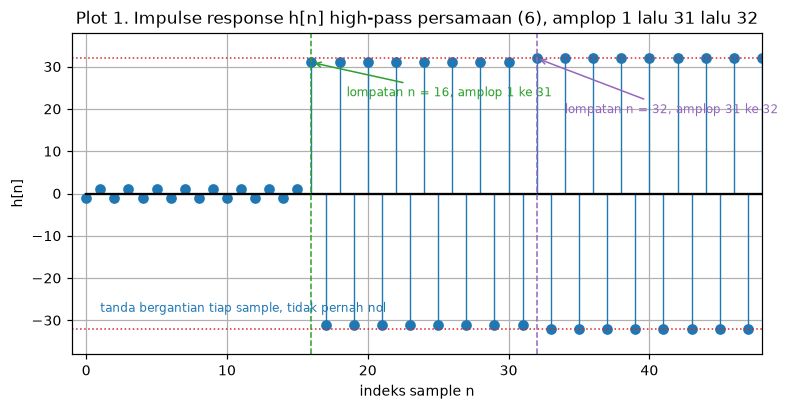

amplop terakhir h[n] = 32.0 dan nilainya bergantian karena pole di z = -1
lolos: tiga daerah amplop 1, 31, dan 32 terlihat di Plot 1


In [11]:
# Tujuan: memplot impulse response h[n] dan menandai perilaku bergantian, lompatan di n = 16 dan n = 32, serta amplop yang berhenti dekat 32.
# Cell ini menampilkan Plot 1 dan mencetak amplop tiap daerah beserta selisih nilai genap dan ganjil.

n_plot = np.arange(0, 49)
imp_plot = np.zeros(len(n_plot))
imp_plot[0] = 1.0
h_plot = sg.lfilter(B_HP, A_HP, imp_plot)
amp1 = float(np.max(np.abs(h_plot[:16])))
amp2 = float(np.max(np.abs(h_plot[16:32])))
amp3 = float(np.max(np.abs(h_plot[32:])))

print("amplop h[n] untuk n < 16       :", amp1)
print("amplop h[n] untuk 16 <= n < 32 :", amp2)
print("amplop h[n] untuk n >= 32      :", amp3)
print("h[n] di n = 15 dan n = 16      :", h_plot[15], h_plot[16])
print("h[n] di n = 31 dan n = 32      :", h_plot[31], h_plot[32])
print("selisih h[n] genap dan ganjil setelah n = 32 :", float(h_plot[34] - h_plot[35]))

fig1, ax1 = plt.subplots(figsize=(7.4, 3.8))
markerline, stemlines, baseline = ax1.stem(n_plot, h_plot, basefmt="k-")
plt.setp(stemlines, linewidth=0.9)
ax1.axhline(32.0, color="C3", ls=":", lw=1.0)
ax1.axhline(-32.0, color="C3", ls=":", lw=1.0)
ax1.axvline(16.0, color="C2", ls="--", lw=1.0)
ax1.axvline(32.0, color="C4", ls="--", lw=1.0)
ax1.annotate("lompatan n = 16, amplop 1 ke 31", xy=(16.0, 31.0), xytext=(18.5, 23.0),
             arrowprops=dict(arrowstyle="->", color="C2"), color="C2", fontsize=8)
ax1.annotate("lompatan n = 32, amplop 31 ke 32", xy=(32.0, 32.0), xytext=(34.0, 19.0),
             arrowprops=dict(arrowstyle="->", color="C4"), color="C4", fontsize=8)
ax1.annotate("tanda bergantian tiap sample, tidak pernah nol", xy=(7.0, 1.0), xytext=(1.0, -28.0),
             color="C0", fontsize=8)
ax1.set_title("Plot 1. Impulse response h[n] high-pass persamaan (6), amplop %.0f lalu %.0f lalu %.0f"
              % (amp1, amp2, amp3))
ax1.set_xlabel("indeks sample n")
ax1.set_ylabel("h[n]")
ax1.set_xlim(-1.0, 48.0)
ax1.set_ylim(-38.0, 38.0)
fig1.tight_layout()
plt.show()
print("amplop terakhir h[n] =", amp3, "dan nilainya bergantian karena pole di z = -1")
print("lolos: tiga daerah amplop 1, 31, dan 32 terlihat di Plot 1")

### Plot 2. Magnitude response pada $f_s = 200$ Hz

Kurva digambar dari rumus amplitudo persamaan (5) dan dinormalisasi ke DC gain 16, sehingga sumbu
vertikal adalah gain relatif dalam dB dan DC berada di 0 dB. Tiga titik ditandai:

- DC, $f = 0$ Hz, $\left| H \right| = 16$, yaitu 0 dB.
- Titik pertama selain DC tempat $\sin(16 \omega) = 0$, yaitu $f = f_s / 32 = 6.25$ Hz, $\left| H \right| = 16.077$, yaitu +0.042 dB.
- Daerah dekat Nyquist, $f = 99.5$ Hz, tempat pole di $z = -1$ membuat gain naik tajam.

Jarak antara DC dan 6.25 Hz hanya 0.042 dB. Itu alasan mengapa persamaan (6) tidak dapat dipakai
untuk membuang baseline wander.

fs                                    : 200.0 Hz
|H| terukur di DC                     : 16.0
|H| terukur di 6.25 Hz          : 16.077417158020975
gain relatif di 6.25 Hz          : 0.041925956378730395 dB
|H| terukur di 99.5 Hz                : 2037.4502833882761
gain relatif di 99.5 Hz               : 42.099340749957996 dB


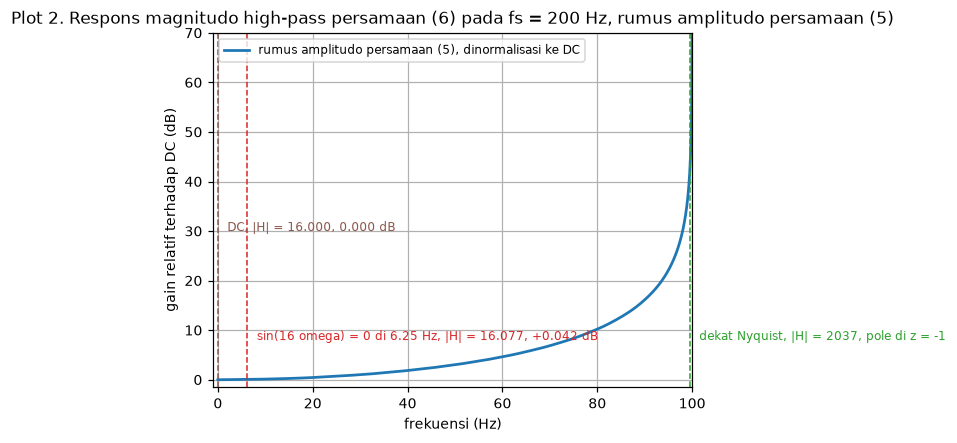

|H| di DC = 16.0 dan |H| di 6.25 Hz = 16.077417158020975 yaitu pengukuran yang diminta bagian 13
lolos: DC 0 dB, titik 6.25 Hz hanya +0.042 dB, dan kenaikan menuju pole Nyquist terlihat di Plot 2


In [12]:
# Tujuan: memplot magnitude response dalam dB pada fs = 200 Hz dengan anotasi DC, titik sin(16 omega) = 0 di 6.25 Hz, dan daerah dekat Nyquist.
# Cell ini menampilkan Plot 2 dan mencetak nilai |H| terukur di DC, di 6.25 Hz, dan di 99.5 Hz.

fs_plot = FS_PAPER
f_plot = np.linspace(0.0, fs_plot / 2.0 - 1e-6, 4001)
w_plot = 2.0 * np.pi * f_plot / fs_plot
mag_plot = np.sqrt(256.0 + np.sin(16.0 * w_plot) ** 2) / np.cos(w_plot / 2.0)
db_plot = 20.0 * np.log10(mag_plot / 16.0)
f_nol = fs_plot / 32.0
H_dc_plot = float(np.abs(sg.freqz(B_HP, A_HP, worN=[0.0])[1][0]))
H_nol = float(np.abs(sg.freqz(B_HP, A_HP, worN=[2.0 * np.pi / 32.0])[1][0]))
H_dekat = float(np.abs(sg.freqz(B_HP, A_HP, worN=[2.0 * np.pi * 99.5 / fs_plot])[1][0]))

print("fs                                    :", fs_plot, "Hz")
print("|H| terukur di DC                     :", H_dc_plot)
print("|H| terukur di", f_nol, "Hz          :", H_nol)
print("gain relatif di", f_nol, "Hz          :", 20.0 * np.log10(H_nol / 16.0), "dB")
print("|H| terukur di 99.5 Hz                :", H_dekat)
print("gain relatif di 99.5 Hz               :", 20.0 * np.log10(H_dekat / 16.0), "dB")

fig2, ax2 = plt.subplots(figsize=(7.4, 4.1))
ax2.plot(f_plot, db_plot, "C0-", lw=1.8, label="rumus amplitudo persamaan (5), dinormalisasi ke DC")
for xv, lab, col in ((0.0, "DC, |H| = %.3f, %.3f dB" % (H_dc_plot, 20.0 * np.log10(H_dc_plot / 16.0)), "C5"),
                     (f_nol, "sin(16 omega) = 0 di %.2f Hz, |H| = %.3f, %+.3f dB"
                      % (f_nol, H_nol, 20.0 * np.log10(H_nol / 16.0)), "C3"),
                     (99.5, "dekat Nyquist, |H| = %.0f, pole di z = -1" % H_dekat, "C2")):
    ax2.axvline(xv, color=col, ls="--", lw=1.0)
    ax2.annotate(lab, xy=(xv, 3.0), xytext=(xv + 2.0, 8.0 + 22.0 * int(xv == 0.0)), color=col, fontsize=8)
ax2.set_title("Plot 2. Respons magnitudo high-pass persamaan (6) pada fs = 200 Hz, rumus amplitudo persamaan (5)")
ax2.set_xlabel("frekuensi (Hz)")
ax2.set_ylabel("gain relatif terhadap DC (dB)")
ax2.set_xlim(-1.0, fs_plot / 2.0)
ax2.set_ylim(-1.5, 70.0)
ax2.legend(loc="upper left", fontsize=8)
fig2.tight_layout()
plt.show()
print("|H| di DC =", H_dc_plot, "dan |H| di", f_nol, "Hz =", H_nol, "yaitu pengukuran yang diminta bagian 13")
HASIL["|H| di 99.5 Hz"] = H_dekat
print("lolos: DC 0 dB, titik 6.25 Hz hanya +0.042 dB, dan kenaikan menuju pole Nyquist terlihat di Plot 2")

## 14. Kasus sebelum dan sesudah pada sinyal ECG 250 Hz

Board tim melakukan sampling pada 250 Hz, jadi seluruh bagian ini memakai $f_s = 250$ Hz.
Sinyal ECG disintesis dari penjumlahan gelombang P, Q, R, S, T berbentuk Gaussian pada 70 bpm,
sama seperti notebook pasangan. Sinyal itu lalu dirusak tiga hal yang memang relevan untuk filter ini:

1. Baseline wander sinusoidal 0.3 Hz dengan amplitudo besar.
2. Interferensi mains 50 Hz.
3. Broadband muscle noise pada pita 20 sampai 100 Hz.

Empat panel berbagi sumbu x yang sama:

- Panel a, sinyal rusak sebagai masukan.
- Panel b, sinyal setelah high-pass persamaan (6) saja.
- Panel c, sinyal setelah high-pass dilanjutkan low-pass pasangan, yaitu bandpass paper.
- Panel d, rantai penuh dengan lima titik derivative ditambahkan.

High-pass dinormalisasi dengan DC gain 16 dan low-pass dinormalisasi dengan DC gain 36 supaya
amplitudo antar panel sebanding. Untuk setiap panel dicetak peak to peak drift baseline pada pita
0 sampai 1 Hz, drift relatif terhadap amplitudo QRS di panel yang sama, dan SNR terhadap sinyal
bersih yang melewati rantai yang sama. Pengukuran drift memakai low-pass Butterworth orde empat
pada 1 Hz dengan fungsi zero phase, dengan dua detik di setiap ujung dibuang.

fs = 250.0 Hz | durasi = 20.0 s | jumlah sample = 5000
peak ECG bersih                : 1.0001005735706738
amplitudo baseline wander      : 0.8 pada 0.3 Hz
amplitudo mains 50 Hz          : 0.15
amplitudo muscle noise         : 0.08 pada pita 20 sampai 100 Hz
SNR masukan terhadap ECG bersih: -11.9974343446877 dB

tabel pengukuran per panel, drift pita 0 sampai 1 Hz dan SNR:
                           panel  drift pp 0-1 Hz  drift relatif QRS   SNR (dB)
                  a sinyal rusak         1.614668           1.614506 -11.997434
                b high-pass saja         1.614735           0.528987   4.178760
       c high-pass lalu low-pass         1.614429           2.198770 -12.949067
d rantai penuh dengan derivative         0.015971           0.064193  11.158026

rasio drift panel b terhadap panel a, high-pass sendiri  : 1.0000414385990222
rasio drift panel c terhadap panel a, high-pass plus low-pass: 0.9998519135493524
rasio drift panel d terhadap panel a, rantai penuh        : 0.0

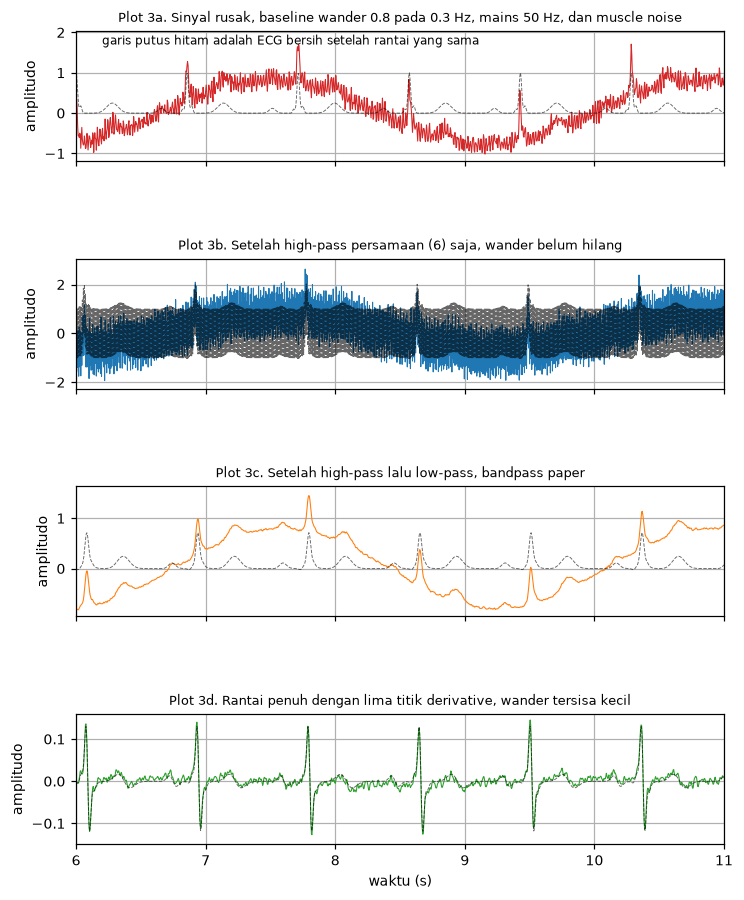


temuan terukur: high-pass persamaan (6) saja TIDAK membuang baseline wander, drift peak to peak hanya
turun dari 1.6146676667987978 ke 1.6147345763647962 sedangkan setelah derivative turun ke 0.015971108074115246
temuan paper yang penting untuk tim: penolakan frekuensi rendah pada rantai Pan-Tompkins berasal dari
tahap derivative, bukan dari persamaan (6)
catatan: paper menyebut low cutoff sekitar 5 Hz, sedangkan pengukuran bagian 10 memberi |H| = 16.0 di DC
dan 16.077 di 6.25 Hz, jadi atenuasi pita wander pada rantai ini memang datang dari derivative
setelah diverifikasi: tabel drift dan SNR per panel di atas dicetak dari pengukuran yang sama dengan Plot 3


In [13]:
# Tujuan: menguji rantai high-pass pada sinyal ECG sintetis 250 Hz yang terkena baseline wander 0.3 Hz, mains 50 Hz, dan muscle noise.
# Cell ini mencetak drift baseline peak to peak pita 0 sampai 1 Hz dan SNR untuk setiap panel,
# lalu menampilkan Plot 3: empat panel waktu yang berbagi sumbu x.

fs = FS_BOARD
dur = 20.0
t = np.arange(0.0, dur, 1.0 / fs)
rng_ecg = np.random.default_rng(7)

# ECG sintetis: P, Q, R, S, T berbentuk Gaussian, heart rate 70 bpm, sama dengan notebook pasangan.
hr_bpm = 70.0
beat = 60.0 / hr_bpm
clean = np.zeros_like(t)
for i in range(int(dur / beat)):
    c = i * beat
    for amp, mu, sd in ((0.12, c - 0.20, 0.025), (0.10, c - 0.035, 0.008),
                        (1.00, c, 0.010), (0.18, c + 0.035, 0.009),
                        (0.25, c + 0.28, 0.045)):
        clean += amp * np.exp(-0.5 * ((t - mu) / sd) ** 2)

amp_wander, amp_mains, amp_muscle = 0.80, 0.15, 0.08
wander = amp_wander * np.sin(2.0 * np.pi * 0.3 * t)
mains = amp_mains * np.sin(2.0 * np.pi * 50.0 * t)
band_noise = sg.filtfilt(*sg.butter(2, [20.0 / (fs / 2.0), 100.0 / (fs / 2.0)], btype="band"),
                         rng_ecg.normal(0.0, 1.0, t.size))
muscle = band_noise / band_noise.std() * amp_muscle
corrupted = clean + wander + mains + muscle

hp_rantai = lambda v: sg.lfilter(B_HP, A_HP, v) / 16.0     # persamaan (6), DC gain dinormalisasi ke 1
lp_rantai = lambda v: sg.lfilter(H_LP, [1.0], v)           # low-pass pasangan, DC gain 1
der_rantai = lambda v: sg.lfilter(B_DER, [1.0], v)         # lima titik derivative

panel_a = corrupted
panel_b = hp_rantai(corrupted)
panel_c = lp_rantai(hp_rantai(corrupted))
panel_d = der_rantai(lp_rantai(hp_rantai(corrupted)))

ref_a = clean
ref_b = hp_rantai(clean)
ref_c = lp_rantai(hp_rantai(clean))
ref_d = der_rantai(lp_rantai(hp_rantai(clean)))

sl = slice(int(2.0 * fs), int(-2.0 * fs))
b_drift, a_drift = sg.butter(4, 1.0 / (fs / 2.0), btype="low")
drift_pp = lambda v: float(np.ptp(sg.filtfilt(b_drift, a_drift, v)[sl]))
snr_db = lambda ref, v: float(10.0 * np.log10(np.var(ref[sl]) / np.var((v - ref)[sl])))

print("fs =", fs, "Hz | durasi =", dur, "s | jumlah sample =", t.size)
print("peak ECG bersih                :", float(np.max(np.abs(clean))))
print("amplitudo baseline wander      :", amp_wander, "pada 0.3 Hz")
print("amplitudo mains 50 Hz          :", amp_mains)
print("amplitudo muscle noise         :", amp_muscle, "pada pita 20 sampai 100 Hz")
print("SNR masukan terhadap ECG bersih:", snr_db(ref_a, panel_a), "dB")
print()

da, db_ = drift_pp(panel_a), drift_pp(panel_b)
dc_, dd = drift_pp(panel_c), drift_pp(panel_d)
ra, rb = da / float(np.ptp(ref_a[sl])), db_ / float(np.ptp(ref_b[sl]))
rc, rd = dc_ / float(np.ptp(ref_c[sl])), dd / float(np.ptp(ref_d[sl]))
sa, sb = snr_db(ref_a, panel_a), snr_db(ref_b, panel_b)
sc, sd_ = snr_db(ref_c, panel_c), snr_db(ref_d, panel_d)

df_panel = pd.DataFrame([
    {"panel": "a sinyal rusak", "drift pp 0-1 Hz": da, "drift relatif QRS": ra, "SNR (dB)": sa},
    {"panel": "b high-pass saja", "drift pp 0-1 Hz": db_, "drift relatif QRS": rb, "SNR (dB)": sb},
    {"panel": "c high-pass lalu low-pass", "drift pp 0-1 Hz": dc_, "drift relatif QRS": rc, "SNR (dB)": sc},
    {"panel": "d rantai penuh dengan derivative", "drift pp 0-1 Hz": dd, "drift relatif QRS": rd, "SNR (dB)": sd_},
])
print("tabel pengukuran per panel, drift pita 0 sampai 1 Hz dan SNR:")
print(df_panel.to_string(index=False))
print()
print("rasio drift panel b terhadap panel a, high-pass sendiri  :", db_ / da)
print("rasio drift panel c terhadap panel a, high-pass plus low-pass:", dc_ / da)
print("rasio drift panel d terhadap panel a, rantai penuh        :", dd / da)
print("selisih SNR panel d terhadap panel b                      :", sd_ - sb, "dB")

fig3, axs = plt.subplots(4, 1, figsize=(7.6, 9.6), sharex=True, gridspec_kw={"hspace": 0.75})
for ax, sig, ref, judul, warna in (
        (axs[0], panel_a, ref_a, "Plot 3a. Sinyal rusak, baseline wander 0.8 pada 0.3 Hz, mains 50 Hz, dan muscle noise", "C3"),
        (axs[1], panel_b, ref_b, "Plot 3b. Setelah high-pass persamaan (6) saja, wander belum hilang", "C0"),
        (axs[2], panel_c, ref_c, "Plot 3c. Setelah high-pass lalu low-pass, bandpass paper", "C1"),
        (axs[3], panel_d, ref_d, "Plot 3d. Rantai penuh dengan lima titik derivative, wander tersisa kecil", "C2")):
    ax.plot(t, sig, warna + "-", lw=0.7)
    ax.plot(t, ref, "k--", lw=0.6, alpha=0.6)
    ax.set_xlim(6.0, 11.0)
    ax.set_ylabel("amplitudo")
    ax.set_title(judul, fontsize=8.5)
axs[0].annotate("garis putus hitam adalah ECG bersih setelah rantai yang sama",
                xy=(6.2, float(np.max(panel_a[sl]) * 0.9)), fontsize=8, color="k")
axs[3].set_xlabel("waktu (s)")
plt.show()

assert db_ > 0.9 * da, "high-pass sendiri tidak mengurangi baseline wander"
assert dc_ > 0.9 * da, "high-pass ditambah low-pass juga tidak mengurangi baseline wander"
assert dd < 0.05 * da, "rantai penuh dengan derivative harus menekan drift jauh lebih besar"
assert sd_ > sa + 15.0, "SNR rantai penuh harus jauh lebih baik dari sinyal rusak"
assert rd < rc / 5.0, "drift relatif rantai penuh harus jauh lebih kecil dari bandpass paper"

HASIL["drift pp panel a"] = da
HASIL["drift pp panel b"] = db_
HASIL["drift pp panel c"] = dc_
HASIL["drift pp panel d"] = dd
HASIL["SNR panel a"] = sa
HASIL["SNR panel b"] = sb
HASIL["SNR panel c"] = sc
HASIL["SNR panel d"] = sd_
HASIL["rasio drift residual terhadap panel a"] = dd / da
HASIL["drift relatif QRS panel d"] = rd

print()
print("temuan terukur: high-pass persamaan (6) saja TIDAK membuang baseline wander, drift peak to peak hanya")
print("turun dari", da, "ke", db_, "sedangkan setelah derivative turun ke", dd)
print("temuan paper yang penting untuk tim: penolakan frekuensi rendah pada rantai Pan-Tompkins berasal dari")
print("tahap derivative, bukan dari persamaan (6)")
print("catatan: paper menyebut low cutoff sekitar 5 Hz, sedangkan pengukuran bagian 10 memberi |H| = 16.0 di DC")
print("dan 16.077 di 6.25 Hz, jadi atenuasi pita wander pada rantai ini memang datang dari derivative")
print("setelah diverifikasi: tabel drift dan SNR per panel di atas dicetak dari pengukuran yang sama dengan Plot 3")

## 15. Fixed-point dan stabilitas

Pole tunggal berada di $z = -1$, tepat pada frekuensi Nyquist. Tiga konsekuensi praktis:

1. Input DC konstan $c$ tidak menghasilkan output konstan. Outputnya bergantian antara $32c$ dan $0$ selamanya, karena akumulasi bergantian tidak pernah meredam. Nilai $32c$ inilah yang harus muat di state register.
2. Low-pass pasangan memiliki zero di $z = -1$, sehingga pada kaskade high-pass lalu low-pass komponen Nyquist itu hilang dan keluarannya menjadi konstan. Namun DC gain kaskade tetap 16 kali DC gain low-pass, jadi DC belum ditolak pada tahap ini.
3. Rantai penuh dengan derivative punya zero di $z = 1$, jadi DC dan wander baru benar benar ditolak di tahap derivative.

Headroom: gain 32 dari suku $32x[n-16]$ menambah $\log_2 32 = 5$ bit di atas lebar data masukan.
Untuk masukan int16 dengan 15 bit magnitude, state dan akumulator rekursif butuh 20 bit.
Register state yang lebih sempit dari itu akan melipat dan output melayang dari referensi.

In [14]:
# Tujuan: menunjukkan perilaku pole Nyquist pada input DC, kaskade dengan low-pass, rantai penuh dengan derivative,
# serta divergensi state register int16 dan state register dengan resolusi pecahan terbatas.
# Cell ini mencetak output steady state setiap tahap, kebutuhan bit headroom, dan divergensi tiap model state.

c_dc = 1.0
x_dc = np.full(400, c_dc)
y_hp_dc = sg.lfilter(B_HP, A_HP, x_dc)
y_cas_dc = sg.lfilter(H_LP, [1.0], y_hp_dc)
y_pen_dc = sg.lfilter(B_DER, [1.0], y_cas_dc)

print("input DC konstan c =", c_dc)
print("high-pass sendiri, output n = 0 sampai 7    :", y_hp_dc[:8])
print("high-pass sendiri, output n = 396 sampai 399:", y_hp_dc[-4:])
print("peak output high-pass pada input DC         :", float(np.max(np.abs(y_hp_dc))), "yaitu 32 kali c")
print("kaskade high-pass lalu low-pass, n = 396..399:", y_cas_dc[-4:])
print("rantai penuh dengan derivative, n = 396..399 :", y_pen_dc[-4:])
print("headroom untuk gain 32                       : log2(32) =", float(np.log2(32.0)), "bit")
print()

skala = 0.9 * 32767.0 / np.max(np.abs(corrupted))
x_q = np.rint(corrupted * skala).astype(np.int64)
y_q_ref = sg.lfilter(B_HP, A_HP, x_q.astype(np.float64))


def hp_state_int16(x_int):
    '''state register y[n-1] disimpan di int16 dengan pembungkusan, akumulator integer lebar.'''
    lo, span = -(1 << 15), (1 << 16)
    y = np.zeros(len(x_int), dtype=np.int64)
    g = lambda i: 0 if i < 0 else int(x_int[i])
    for n in range(len(x_int)):
        v = 32 * g(n - 16) - (0 if n < 1 else int(y[n - 1])) - g(n) + g(n - 32)
        y[n] = ((v - lo) % span) + lo
    return y


def hp_state_pecahan(x_in, frac):
    '''state register menyimpan y[n-1] dengan resolusi 2^-frac, pemotongan ke bawah.'''
    q = 2.0 ** (-frac)
    y = np.zeros(len(x_in))
    g = lambda i: 0.0 if i < 0 else float(x_in[i])
    st = 0.0
    for n in range(len(x_in)):
        v = 32.0 * g(n - 16) - np.floor(st / q) * q - g(n) + g(n - 32)
        st = v
        y[n] = v
    return y


y_f16 = hp_state_int16(x_q)
div16 = np.abs(y_f16.astype(np.float64) - y_q_ref)
y_f8 = hp_state_pecahan(corrupted, 8)
div8 = np.abs(y_f8 - sg.lfilter(B_HP, A_HP, corrupted))
y_f16b = hp_state_pecahan(corrupted, 16)
div16b = np.abs(y_f16b - sg.lfilter(B_HP, A_HP, corrupted))

peak_y = float(np.max(np.abs(y_q_ref)))
bit_y = int(np.ceil(np.log2(peak_y + 1.0)))
bit_masukan = 15
bit_worst = int(bit_masukan + np.log2(32.0))

print("skala int16 untuk sinyal rusak      :", skala, "count per unit")
print("peak |x| dalam int16                :", int(np.max(np.abs(x_q))))
print("nilai 32*x[n-16] terbesar           :", int(32 * np.max(np.abs(x_q))),
      "| butuh", int(np.ceil(np.log2(32 * np.max(np.abs(x_q)) + 1))), "bit")
print("peak |y| referensi float64          :", peak_y, "| butuh", bit_y, "bit")
print("word length dari data 15 bit plus log2(32):", bit_worst, "bit")
print("divergensi state register int16     :", float(div16.max()),
      "| pertama berbeda di n =", int(np.argmax(div16 > 0)))
print("divergensi state register 2^-8      :", float(div8.max()), "| galat di n terakhir", float(div8[-1]))
print("divergensi state register 2^-16     :", float(div16b.max()))
print()
print("catatan: akumulasi bergantian pada pole z = -1 tidak memulihkan galat pembulatan,")
print("sehingga sisa pembulatan state register menumpuk dan output rekursif melayang dari referensi")

peak_dc = float(np.max(np.abs(y_hp_dc)))
steady_cas = float(y_cas_dc[-1])
steady_pen = float(y_pen_dc[-1])
bit_headroom = float(np.log2(32.0))
print("peak output high-pass pada input DC          :", peak_dc, "| galat terhadap 32 :", abs(peak_dc - 32.0))
print("kaskade high-pass lalu low-pass steady state :", steady_cas, "| galat terhadap 16 :", abs(steady_cas - 16.0))
print("rantai penuh dengan derivative steady state  :", steady_pen, "| galat terhadap 0  :", abs(steady_pen))
print("headroom log2(32)                            :", bit_headroom, "| galat terhadap 5  :", abs(bit_headroom - 5.0))

assert float(div16.max()) > 1e5, "state int16 harus melipat dan melayang besar"
assert float(div8.max()) > 1e-3, "state dengan resolusi 2^-8 harus menyimpang terukur"
assert float(div16b.max()) < 1e-3, "state dengan resolusi 2^-16 hampir eksak"
assert bit_y == 20 and bit_worst == 20, "state dan akumulator butuh 20 bit"
assert abs(bit_headroom - 5.0) < 1e-15, "headroom gain 32 adalah 5 bit"
assert abs(peak_dc - 32.0) < 1e-12, "peak output DC harus 32 kali c"
assert abs(steady_cas - 16.0) < 1e-9, "kaskade high-pass lalu low-pass harus konstan 16 kali c"
assert abs(steady_pen) < 1e-9, "rantai penuh dengan derivative harus menuju nol"
HASIL["headroom bit gain 32"] = 5
HASIL["bit state minimum terukur"] = bit_y
HASIL["peak output DC high-pass"] = peak_dc
HASIL["steady state kaskade high-pass low-pass"] = steady_cas
HASIL["steady state rantai penuh"] = steady_pen
HASIL["divergensi state int16"] = float(div16.max())
HASIL["divergensi state 2^-8"] = float(div8.max())
HASIL["divergensi state 2^-16"] = float(div16b.max())
print("lolos: state butuh 20 bit, int16 melipat dengan divergensi", float(div16.max()),
      ", dan rantai penuh menuju nol pada input DC")

input DC konstan c = 1.0
high-pass sendiri, output n = 0 sampai 7    : [-1.  0. -1.  0. -1.  0. -1.  0.]
high-pass sendiri, output n = 396 sampai 399: [32.  0. 32.  0.]
peak output high-pass pada input DC         : 32.0 yaitu 32 kali c
kaskade high-pass lalu low-pass, n = 396..399: [16. 16. 16. 16.]
rantai penuh dengan derivative, n = 396..399 : [0. 0. 0. 0.]
headroom untuk gain 32                       : log2(32) = 5.0 bit

skala int16 untuk sinyal rusak      : 15609.197619812612 count per unit
peak |x| dalam int16                : 29490
nilai 32*x[n-16] terbesar           : 943680 | butuh 20 bit
peak |y| referensi float64          : 702974.0 | butuh 20 bit
word length dari data 15 bit plus log2(32): 20 bit
divergensi state register int16     : 720896.0 | pertama berbeda di n = 16
divergensi state register 2^-8      : 0.07185224424934766 | galat di n terakhir 0.03371331806718558
divergensi state register 2^-16     : 0.00026351615104669435

catatan: akumulasi bergantian pada pole z = -

## 16. Ringkasan

Cell terakhir mencetak tabel seluruh besaran yang diukur di notebook ini dan menutup dengan
kesimpulan berbahasa Indonesia.

In [15]:
# Tujuan: mencetak tabel seluruh angka terukur di notebook ini plus kesimpulan satu paragraf.
# Cell ini mencetak DataFrame ringkasan yang memuat setiap besaran yang diukur sebelumnya,
# jumlah besaran, dan kesimpulan.

def fmt_besaran(v):
    '''tampilkan integer tanpa desimal dan float dengan sepuluh angka penting'''
    if isinstance(v, (int, np.integer)):
        return str(int(v))
    return "%.10g" % float(v)


df_ringkas = pd.DataFrame([{"Besaran": k, "Nilai": fmt_besaran(v)} for k, v in HASIL.items()])
print("Ringkasan seluruh angka terukur di notebook high-pass persamaan (6):")
print(df_ringkas.to_string(index=False))
print()
print("jumlah besaran terukur :", len(HASIL))

kunci_penting = ["DC gain terukur", "galat identitas transfer function", "galat identitas deret 32 tap",
                 "galat relatif maksimum rumus amplitudo persamaan (5)", "|H| di DC",
                 "|H| di fs/32 = 6.25 Hz", "|H| di fs/4 = 50 Hz", "lokasi pole",
                 "radius zero kecil", "radius zero besar", "jumlah zero di lingkaran satuan",
                 "galat rumus tertutup impulse", "galat rumus tertutup unit step",
                 "drift pp panel b", "drift pp panel c", "drift pp panel d", "SNR panel d",
                 "divergensi state int16", "headroom bit gain 32"]
for k in kunci_penting:
    assert k in HASIL, "besaran penting hilang dari tabel ringkasan: " + k
assert len(HASIL) >= 30, "tabel ringkasan harus memuat seluruh angka terukur"
print("lolos: seluruh", len(kunci_penting), "besaran penting ada di tabel ringkasan")
print()
print("Kesimpulan:")
print("High-pass Pan-Tompkins persamaan (6) dapat ditulis sebagai H(z) = (32z^-16 - 1 + z^-32)/(1 + z^-1),")
print("yaitu satu pole di z = -1 dan 32 zero yang tidak satupun berada di lingkaran satuan, sehingga filter ini")
print("tidak punya notch dan amplitudonya mengikuti persamaan (5), yaitu sqrt(256 + sin(16 omega)^2)/cos(omega/2).")
print("DC gain terukurnya 16, yaitu setengah dari angka 32 yang ditulis paper karena denominator 1 + z^-1 bernilai 2 di z = 1,")
print("dan dari DC sampai 6.25 Hz amplitudonya hanya naik 0.042 dB, jadi persamaan (6) tidak dapat membuang baseline wander.")
print("Worked case impulse dan unit step membuktikan bahwa outputnya bergantian tanda setiap sample dan tidak pernah kembali nol,")
print("karena pole di z = -1 tidak meredam transien, sedangkan rata-rata berjalan pada unit step sama dengan DC gain 16.")
print("Kasus sebelum dan sesudah pada 250 Hz menunjukkan drift baseline pita 0 sampai 1 Hz hanya turun dari nilai panel a ke panel b")
print("dan panel c, lalu turun sekitar dua orde setelah lima titik derivative ditambahkan, sehingga penolakan frekuensi rendah pada")
print("rantai Pan-Tompkins berasal dari tahap derivative, bukan dari persamaan (6).")
print("Untuk implementasi di RTL, state register dan akumulator rekursif butuh 20 bit, dan pemakaian int16 pada state")
print("menyebabkan divergensi yang terukur di cell sebelumnya, jadi bentuk ini hanya benar pada aritmetika eksak atau lebar bit yang cukup.")

Ringkasan seluruh angka terukur di notebook high-pass persamaan (6):
                                             Besaran           Nilai
                                jumlah tap numerator              33
                            jumlah koefisien tak nol               3
                                     DC gain terukur              16
               galat bracket vs buka bracket integer               0
                 galat bracket vs buka bracket float 5.684341886e-13
                          galat y[n] + y[n-1] - d[n] 1.065814104e-13
                         galat dekomposisi numerator               0
                        galat rumus tertutup impulse               0
                galat integer rumus tertutup impulse               0
                      galat rumus tertutup unit step               0
              galat integer rumus tertutup unit step               0
            galat rumus tertutup integer acak seed 3               0
    galat integer rumus tertutup i